# Step 2: Exploratory Data Analysis and the "Cost of Doing Nothing"

**Project:** Chargeback Reduction for NovaCart ([business brief](../docs/business_brief.md))

Before building any model, we answer the questions a risk manager would ask:

1. **How big is the problem?** Fraud rate by *count* (what Visa/Mastercard monitor) and by *dollar value* (what hurts the P&L).
2. **Is it stable over time?** Fraud patterns drift, which is why we will split train/test by time.
3. **Where does fraud concentrate?** Order size, product type, card type, email domain.
4. **What does doing nothing cost?** The baseline every later step must beat.
5. **Is the review-capacity assumption realistic?** 100 manual reviews a day against real daily volume.

**Data:** `train_transaction.csv` from the IEEE-CIS Fraud Detection competition (the only file with fraud labels).
We load a curated set of ~45 interpretable columns, not all 394.

In [16]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 50)

# Chart styling: one blue for genuine / overall, one orange for fraud
GENUINE, FRAUD, MUTED = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "lines.linewidth": 2,
})

# Locally (run from notebooks/) outputs go into the repo's reports/ folder;
# on Kaggle they go to /kaggle/working (download them from the Output panel).
OUT_DIR = Path("../reports") if Path("../reports").exists() else Path(".")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load the data

The loader searches the Kaggle input folder first, then a local `data/` folder, so the same notebook runs in both places.
Only the columns we plan to use are read, and text columns are stored as `category` to save memory.

In [17]:
def find_file(name):
    roots = [os.environ.get("FRAUD_DATA_DIR"), "/kaggle/input", "../data", "data"]
    for root in filter(None, roots):
        root = Path(root)
        if root.exists():
            hits = sorted(root.rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(
        f"{name} not found. On Kaggle: Add Input -> Competitions -> IEEE-CIS Fraud Detection. "
        "Locally: put the file in the data/ folder."
    )

# Curated, interpretable columns (see business brief, Section 7)
ID_TARGET_TIME = ["TransactionID", "isFraud", "TransactionDT"]
ORDER          = ["TransactionAmt", "ProductCD"]
CARD           = ["card1", "card2", "card3", "card4", "card5", "card6"]
LOCATION       = ["addr1", "addr2", "dist1"]
EMAIL          = ["P_emaildomain", "R_emaildomain"]
COUNTS         = [f"C{i}" for i in range(1, 15)]   # counting features (e.g. how many addresses linked to the card)
TIMEDELTAS     = ["D1", "D4", "D10", "D15"]        # days since previous events (e.g. D1 ~ days since card first seen)
MATCHES        = [f"M{i}" for i in range(1, 10)]   # match checks (e.g. name on card vs address), T/F
CATEGORICAL    = ["ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain"] + MATCHES

USE_COLS = ID_TARGET_TIME + ORDER + CARD + LOCATION + EMAIL + COUNTS + TIMEDELTAS + MATCHES

path = find_file("train_transaction.csv")
print(f"Loading {path}")
df = pd.read_csv(path, usecols=USE_COLS, dtype={c: "category" for c in CATEGORICAL})

# Shrink numeric columns (money stays float64 so sums are exact to the cent)
for c in df.columns:
    if c in CATEGORICAL or c == "TransactionAmt":
        continue
    if pd.api.types.is_float_dtype(df[c]):
        df[c] = df[c].astype("float32")
    elif pd.api.types.is_integer_dtype(df[c]):
        df[c] = pd.to_numeric(df[c], downcast="integer")

print(f"{len(df):,} transactions x {df.shape[1]} columns | memory: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
df.head()

Loading /kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv
590,540 transactions x 43 columns | memory: 76 MB


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,D1,D4,D10,D15,M1,M2,M3,M4,M5,M6,M7,M8,M9
0,2987000,0,86400,68.5000,W,13926,NaN,150.0000,discover,142.0000,credit,315.0000,87.0000,19.0000,NaN,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,2.0000,0.0000,1.0000,1.0000,14.0000,NaN,13.0000,0.0000,T,T,T,M2,F,T,NaN,NaN,NaN
1,2987001,0,86401,29.0000,W,2755,404.0000,150.0000,mastercard,102.0000,credit,325.0000,87.0000,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,M0,T,T,NaN,NaN,NaN
2,2987002,0,86469,59.0000,W,4663,490.0000,150.0000,visa,166.0000,debit,330.0000,87.0000,287.0000,outlook.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,315.0000,T,T,T,M0,F,F,F,F,F
3,2987003,0,86499,50.0000,W,18132,567.0000,150.0000,mastercard,117.0000,debit,476.0000,87.0000,NaN,yahoo.com,NaN,2.0000,5.0000,0.0000,0.0000,0.0000,4.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,25.0000,1.0000,112.0000,94.0000,84.0000,111.0000,NaN,NaN,NaN,M0,T,F,NaN,NaN,NaN
4,2987004,0,86506,50.0000,H,4497,514.0000,150.0000,mastercard,102.0000,credit,420.0000,87.0000,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. The time axis

`TransactionDT` is a time offset in **seconds** from an undisclosed reference point (the real dates are hidden).
We convert it to a day index. "Months" below are 30-day blocks, which is close enough for monthly business metrics.

In [18]:
df["day"]   = (df["TransactionDT"] // 86_400).astype("int32")
df["day"]  -= df["day"].min()                     # day 0 = first day in the data
df["week"]  = (df["day"] // 7).astype("int16")
df["month"] = (df["day"] // 30).astype("int16")

n_days = df["day"].max() + 1
daily_volume = df.groupby("day").size()

print(f"Time span: {n_days} days (~{n_days / 30:.1f} months)")
print(f"Daily volume: mean {daily_volume.mean():,.0f} | median {daily_volume.median():,.0f} | "
      f"min {daily_volume.min():,} | max {daily_volume.max():,}")

Time span: 182 days (~6.1 months)
Daily volume: mean 3,245 | median 3,050 | min 2,048 | max 6,852


## 3. How big is the problem?

In [19]:
fraud = df["isFraud"] == 1
n_tx, n_fraud = len(df), int(fraud.sum())
revenue      = df["TransactionAmt"].sum()
fraud_amount = df.loc[fraud, "TransactionAmt"].sum()

headline = pd.Series({
    "Transactions":                 f"{n_tx:,}",
    "Fraud transactions":           f"{n_fraud:,}",
    "Fraud rate by COUNT":          f"{n_fraud / n_tx:.2%}",
    "Total order value":            f"${revenue:,.0f}",
    "Fraud order value":            f"${fraud_amount:,.0f}",
    "Fraud rate by DOLLAR VALUE":   f"{fraud_amount / revenue:.2%}",
    "Avg genuine order":            f"${df.loc[~fraud, 'TransactionAmt'].mean():,.2f}",
    "Avg fraud order":              f"${df.loc[fraud, 'TransactionAmt'].mean():,.2f}",
}, name="value")
headline.to_frame()

,value
Transactions,"590,540"
Fraud transactions,"20,663"
Fraud rate by COUNT,3.50%
Total order value,"$79,738,949"
Fraud order value,"$3,083,845"
Fraud rate by DOLLAR VALUE,3.87%
Avg genuine order,$134.51
Avg fraud order,$149.24


**Why two rates?** Card networks count *transactions* (the VAMP ratio is fraud + disputes divided by transactions),
while finance cares about *dollars*. If fraudsters favour larger orders, the dollar rate is higher than the count rate.

### Monthly fraud ratio vs card-network thresholds

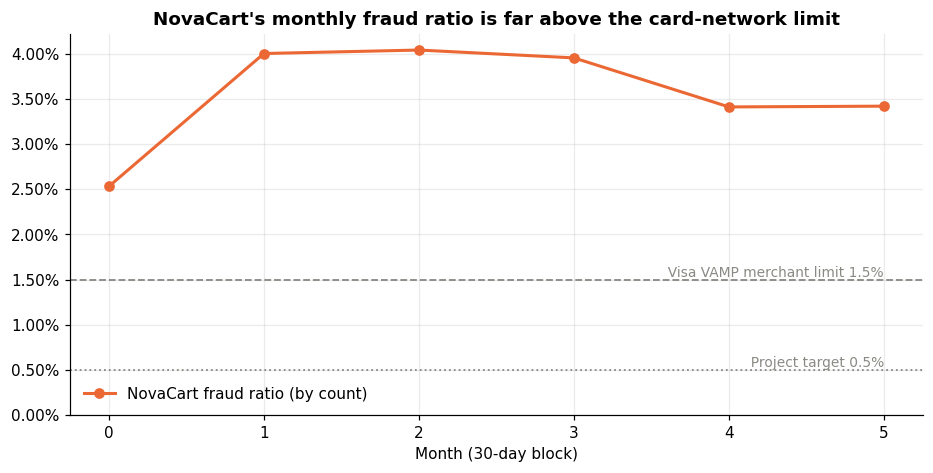

,transactions,frauds,order_value,fraud_value,fraud_ratio_count,fraud_ratio_value,days
month,,,,,,,
0,134339,3401,"17,232,968.4520","461,697.8060",0.0253,0.0268,30
1,89399,3577,"11,937,193.0020","489,558.6560",0.0400,0.0410,30
2,92189,3724,"12,909,216.3840","523,638.7270",0.0404,0.0406,30
3,98615,3898,"13,759,624.6640","658,939.8830",0.0395,0.0479,30
4,83571,2850,"11,173,351.6390","462,547.6030",0.0341,0.0414,30
5,86934,2972,"11,831,816.2340","443,214.4420",0.0342,0.0375,30
6,5493,241,"894,778.3600","44,247.7430",0.0439,0.0495,2


In [20]:
monthly = df.groupby("month").agg(
    transactions=("isFraud", "size"),
    frauds=("isFraud", "sum"),
    order_value=("TransactionAmt", "sum"),
)
monthly["fraud_value"] = df[fraud].groupby("month")["TransactionAmt"].sum()
monthly["fraud_ratio_count"] = monthly["frauds"] / monthly["transactions"]
monthly["fraud_ratio_value"] = monthly["fraud_value"] / monthly["order_value"]
monthly["days"] = df.groupby("month")["day"].nunique()

full_months = monthly[monthly["days"] >= 28]   # a short final block would be noisy

fig, ax = plt.subplots()
ax.plot(full_months.index, full_months["fraud_ratio_count"], marker="o", color=FRAUD, label="NovaCart fraud ratio (by count)")
ax.axhline(0.015, color=MUTED, ls="--", lw=1.2)
ax.axhline(0.005, color=MUTED, ls=":",  lw=1.2)
ax.text(full_months.index.max(), 0.015, "  Visa VAMP merchant limit 1.5%", va="bottom", ha="right", fontsize=9, color=MUTED)
ax.text(full_months.index.max(), 0.005, "  Project target 0.5%", va="bottom", ha="right", fontsize=9, color=MUTED)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, None)
ax.set_xlabel("Month (30-day block)")
ax.set_title("NovaCart's monthly fraud ratio is far above the card-network limit")
ax.legend(loc="lower left", frameon=False)
save(fig, "01_monthly_fraud_ratio"); plt.show()

monthly

**Note:** the chart shows complete 30-day blocks only. A short final block, if any, still appears in the table (see its `days` column).

## 4. Is fraud stable over time?
If the weekly rate moves a lot, a random train/test split would mix "future" patterns into training. That is why Step 3 splits by time.

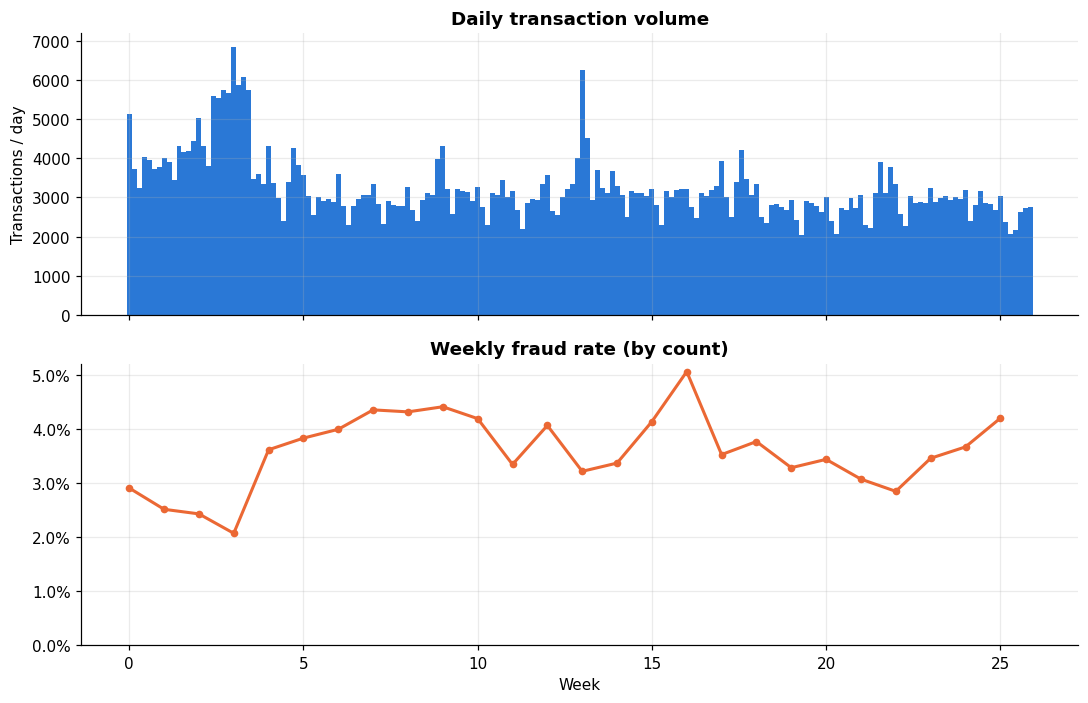

Weekly fraud rate ranges from 2.07% to 5.07%


In [21]:
weekly = df.groupby("week").agg(transactions=("isFraud", "size"), fraud_rate=("isFraud", "mean"))
weekly = weekly[weekly["transactions"] >= 1_000]   # drop a tiny partial last week

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
axes[0].bar(daily_volume.index / 7, daily_volume.values, width=1 / 7, color=GENUINE)
axes[0].set_title("Daily transaction volume")
axes[0].set_ylabel("Transactions / day")
axes[1].plot(weekly.index, weekly["fraud_rate"], color=FRAUD, marker="o", ms=4)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
axes[1].set_ylim(0, None)
axes[1].set_title("Weekly fraud rate (by count)")
axes[1].set_xlabel("Week")
fig.tight_layout()
save(fig, "02_volume_and_weekly_fraud"); plt.show()

print(f"Weekly fraud rate ranges from {weekly['fraud_rate'].min():.2%} to {weekly['fraud_rate'].max():.2%}")

## 5. Where does fraud concentrate?

### Order size

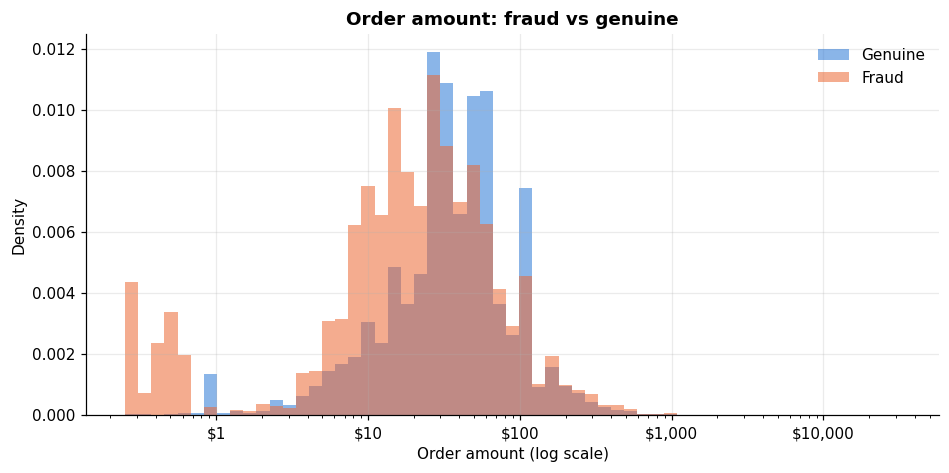

,count,mean,std,min,25%,50%,75%,90%,99%,max
isFraud,,,,,,,,,,
Genuine,"569,877.0000",134.5117,239.3951,0.2510,43.9700,68.5000,120.0000,267.1120,"1,104.0000","31,937.3910"
Fraud,"20,663.0000",149.2448,232.2122,0.2920,35.0440,75.0000,161.0000,335.0000,994.0000,"5,191.0000"


In [22]:
fig, ax = plt.subplots()
bins = np.logspace(np.log10(max(df["TransactionAmt"].min(), 0.25)), np.log10(df["TransactionAmt"].max()), 60)
ax.hist(df.loc[~fraud, "TransactionAmt"], bins=bins, density=True, alpha=0.55, color=GENUINE, label="Genuine")
ax.hist(df.loc[fraud,  "TransactionAmt"], bins=bins, density=True, alpha=0.55, color=FRAUD,   label="Fraud")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("Order amount (log scale)")
ax.set_ylabel("Density")
ax.set_title("Order amount: fraud vs genuine")
ax.legend(frameon=False)
save(fig, "03_amount_distribution"); plt.show()

df.groupby("isFraud")["TransactionAmt"].describe(percentiles=[.25, .5, .75, .9, .99]).rename(index={0: "Genuine", 1: "Fraud"})

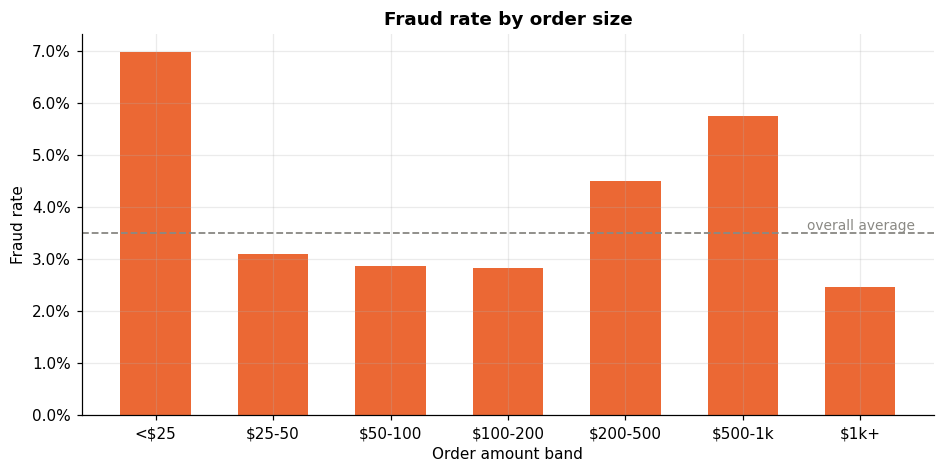

,transactions,fraud_rate,fraud_value,share_of_fraud_dollars
amount_band,,,,
<$25,43329,0.0697,"46,756.0570",0.0152
$25-50,144186,0.0309,"163,935.9920",0.0532
$50-100,160742,0.0287,"320,696.3210",0.1040
$100-200,141813,0.0282,"526,380.7060",0.1707
$200-500,76146,0.0449,"1,017,352.8130",0.3299
$500-1k,16744,0.0575,"699,792.6110",0.2269
$1k+,7580,0.0247,"308,930.3600",0.1002


In [23]:
amount_bands = [0, 25, 50, 100, 200, 500, 1_000, np.inf]
band_labels  = ["<$25", "$25-50", "$50-100", "$100-200", "$200-500", "$500-1k", "$1k+"]
df["amount_band"] = pd.cut(df["TransactionAmt"], amount_bands, labels=band_labels, right=False)

df["fraud_amt"] = df["TransactionAmt"] * df["isFraud"]   # order value if fraud, else 0
by_band = df.groupby("amount_band", observed=True).agg(
    transactions=("isFraud", "size"), fraud_rate=("isFraud", "mean"), fraud_value=("fraud_amt", "sum"))
by_band["share_of_fraud_dollars"] = by_band["fraud_value"] / by_band["fraud_value"].sum()

fig, ax = plt.subplots()
ax.bar(by_band.index.astype(str), by_band["fraud_rate"], color=FRAUD, width=0.6)
ax.axhline(fraud.mean(), color=MUTED, ls="--", lw=1.2)
ax.text(len(by_band) - 0.5, fraud.mean(), "overall average ", ha="right", va="bottom", fontsize=9, color=MUTED)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Order amount band")
ax.set_ylabel("Fraud rate")
ax.set_title("Fraud rate by order size")
save(fig, "04_fraud_rate_by_amount"); plt.show()

by_band

### Product, card and email signals
`fraud_rate_by` shows, for each value of a column: how many transactions, the fraud rate, and the **lift**
(fraud rate ÷ overall rate; a lift of 3 means three times riskier than average). Rare values are grouped so small samples don't mislead.

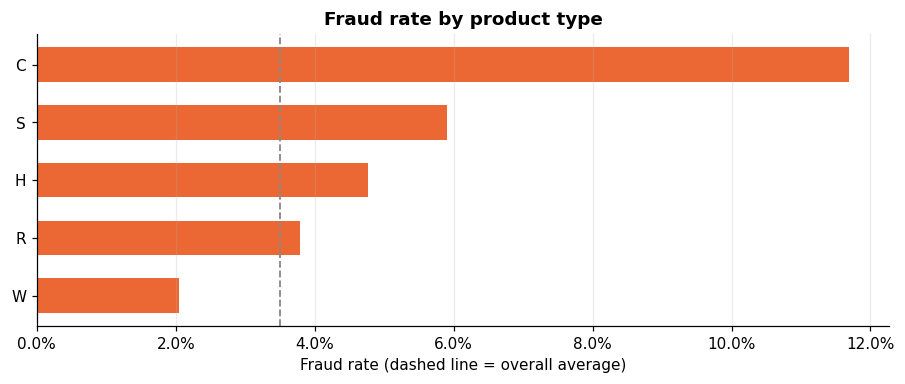

,transactions,fraud_rate,share_of_volume,lift
ProductCD,,,,
W,439670,0.0204,0.7445,0.5830
C,68519,0.1169,0.1160,3.3402
R,37699,0.0378,0.0638,1.0810
H,33024,0.0477,0.0559,1.3622
S,11628,0.0590,0.0197,1.6861


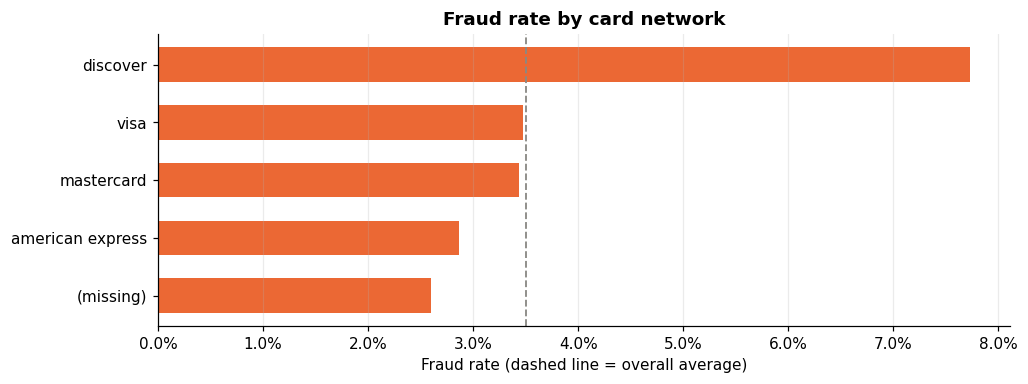

,transactions,fraud_rate,share_of_volume,lift
card4,,,,
visa,384767,0.0348,0.6516,0.9933
mastercard,189217,0.0343,0.3204,0.9812
american express,8328,0.0287,0.0141,0.8202
discover,6651,0.0773,0.0113,2.2087
(missing),1577,0.0260,0.0027,0.7430


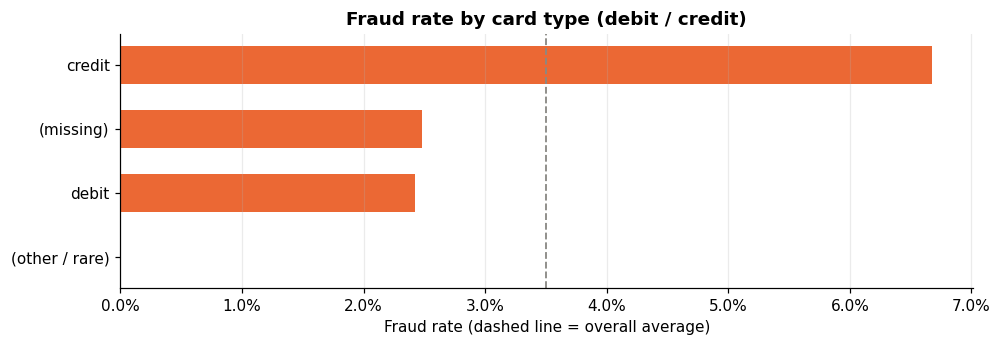

,transactions,fraud_rate,share_of_volume,lift
card6,,,,
debit,439938,0.0243,0.7450,0.6934
credit,148986,0.0668,0.2523,1.9087
(missing),1571,0.0248,0.0027,0.7095
(other / rare),45,0.0000,0.0001,0.0000


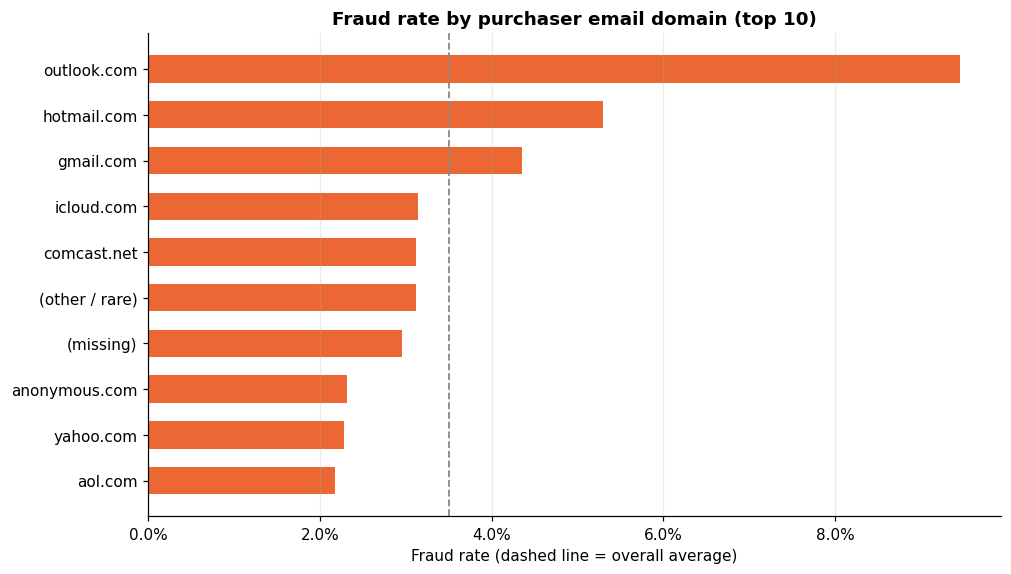

,transactions,fraud_rate,share_of_volume,lift
P_emaildomain,,,,
gmail.com,228355,0.0435,0.3867,1.2444
yahoo.com,100934,0.0228,0.1709,0.6504
(missing),94456,0.0295,0.1599,0.8442
hotmail.com,45250,0.0530,0.0766,1.5133
anonymous.com,36998,0.0232,0.0627,0.6635
aol.com,28289,0.0218,0.0479,0.6233
comcast.net,7888,0.0312,0.0134,0.8913
(other / rare),7090,0.0312,0.0120,0.8908
icloud.com,6267,0.0314,0.0106,0.8984


In [24]:
OVERALL = fraud.mean()

def fraud_rate_by(col, top=10, min_count=500):
    s = df[col].astype("object").fillna("(missing)")
    counts = s.value_counts()
    s = s.where(s.map(counts) >= min_count, "(other / rare)")
    t = df.groupby(s, observed=True)["isFraud"].agg(transactions="size", fraud_rate="mean")
    t["share_of_volume"] = t["transactions"] / len(df)
    t["lift"] = t["fraud_rate"] / OVERALL
    return t.sort_values("transactions", ascending=False).head(top)

def plot_rates(table, title, name):
    t = table.sort_values("fraud_rate")
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(t) + 1.2))
    ax.barh(t.index.astype(str), t["fraud_rate"], color=FRAUD, height=0.6)
    ax.axvline(OVERALL, color=MUTED, ls="--", lw=1.2)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_xlabel("Fraud rate (dashed line = overall average)")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    save(fig, name); plt.show()

for col, title, name in [
    ("ProductCD",     "Fraud rate by product type",                 "05_product"),
    ("card4",         "Fraud rate by card network",                 "06_card_network"),
    ("card6",         "Fraud rate by card type (debit / credit)",   "07_card_type"),
    ("P_emaildomain", "Fraud rate by purchaser email domain (top 10)", "08_email_domain"),
]:
    t = fraud_rate_by(col)
    plot_rates(t, title, name)
    display(t)

### Missing values
Missing values are common in IEEE-CIS. LightGBM handles them natively, and **"missing" can itself be a signal**:
for example, a missing recipient email domain may behave differently from a filled one.

In [25]:
miss = pd.DataFrame({
    "missing_%": df[USE_COLS].isna().mean(),
    "fraud_rate_when_missing": [df.loc[df[c].isna(), "isFraud"].mean() if df[c].isna().any() else np.nan for c in USE_COLS],
    "fraud_rate_when_present": [df.loc[df[c].notna(), "isFraud"].mean() for c in USE_COLS],
}).sort_values("missing_%", ascending=False)
miss[miss["missing_%"] > 0]

,missing_%,fraud_rate_when_missing,fraud_rate_when_present
R_emaildomain,0.7675,0.0208,0.0818
dist1,0.5965,0.0452,0.0200
M5,0.5935,0.0374,0.0315
M7,0.5864,0.0458,0.0197
M8,0.5863,0.0458,0.0197
M9,0.5863,0.0458,0.0197
M4,0.4766,0.0186,0.0499
M1,0.4591,0.0528,0.0199
M2,0.4591,0.0528,0.0199
M3,0.4591,0.0528,0.0199


## 6. The cost of doing nothing

Today NovaCart screens nothing, so **every fraudulent order is shipped and later charged back**.
The assumptions below come from the business brief and are kept in one dictionary so later steps (and the dashboard) reuse them.

| Cost item | Assumption | Source |
|---|---|---|
| Lost order | Full order amount (goods shipped, money reversed) | Brief, Section 6 |
| Chargeback fee | $25 per chargeback | Typical processor range $15-$100 |
| Network fine | ~$8 per fraud transaction while above Visa's 1.5% limit | Visa VAMP |

We **do not** add the LexisNexis $4.61-per-$1 multiplier on top: it is an industry average of *all* hidden costs and would double-count
the items above. We quote it only as context for how conservative this baseline is.

In [26]:
ASSUMPTIONS = {
    "chargeback_fee": 25.0,       # $ per chargeback
    "vamp_fine": 8.0,             # $ per fraud transaction in months above the network limit
    "vamp_limit": 0.015,          # Visa VAMP merchant threshold (fraud ratio by count)
    "target_ratio": 0.005,        # project target
    "review_capacity_per_day": 100,
}

m = monthly.copy()
m["over_limit"]      = m["fraud_ratio_count"] > ASSUMPTIONS["vamp_limit"]
m["lost_orders_$"]   = m["fraud_value"]
m["chargeback_fees_$"] = m["frauds"] * ASSUMPTIONS["chargeback_fee"]
m["network_fines_$"] = np.where(m["over_limit"], m["frauds"] * ASSUMPTIONS["vamp_fine"], 0.0)
m["total_cost_$"]    = m[["lost_orders_$", "chargeback_fees_$", "network_fines_$"]].sum(axis=1)
m["cost_%_of_revenue"] = m["total_cost_$"] / m["order_value"]

full = m[m["days"] >= 28]   # use complete months for monthly averages
baseline = {
    "total_cost_$": float(m["total_cost_$"].sum()),
    "avg_monthly_cost_$": float(full["total_cost_$"].mean()),
    "cost_pct_of_revenue": float(m["total_cost_$"].sum() / m["order_value"].sum()),
    "fraud_ratio_count": float(n_fraud / n_tx),
    "fraud_ratio_value": float(fraud_amount / revenue),
    "months_over_vamp_limit": int(m["over_limit"].sum()),
    "months_total": int(len(m)),
}

cost_cols = ["transactions", "frauds", "fraud_ratio_count", "lost_orders_$", "chargeback_fees_$",
             "network_fines_$", "total_cost_$", "cost_%_of_revenue"]
display(m[cost_cols].style.format({
    "transactions": "{:,}", "frauds": "{:,}", "fraud_ratio_count": "{:.2%}",
    "lost_orders_$": "${:,.0f}", "chargeback_fees_$": "${:,.0f}", "network_fines_$": "${:,.0f}",
    "total_cost_$": "${:,.0f}", "cost_%_of_revenue": "{:.2%}",
}))

print(f"Total cost of doing nothing over {n_days} days: ${baseline['total_cost_$']:,.0f}")
print(f"Average per full month:                         ${baseline['avg_monthly_cost_$']:,.0f}")
print(f"Cost as % of revenue:                           {baseline['cost_pct_of_revenue']:.2%}")
print(f"Months above the 1.5% VAMP limit:               {baseline['months_over_vamp_limit']} of {baseline['months_total']}")

,transactions,frauds,fraud_ratio_count,lost_orders_$,chargeback_fees_$,network_fines_$,total_cost_$,cost_%_of_revenue
month,,,,,,,,
0,"134,339","3,401",2.53%,"$461,698","$85,025","$27,208","$573,931",3.33%
1,"89,399","3,577",4.00%,"$489,559","$89,425","$28,616","$607,600",5.09%
2,"92,189","3,724",4.04%,"$523,639","$93,100","$29,792","$646,531",5.01%
3,"98,615","3,898",3.95%,"$658,940","$97,450","$31,184","$787,574",5.72%
4,"83,571","2,850",3.41%,"$462,548","$71,250","$22,800","$556,598",4.98%
5,"86,934","2,972",3.42%,"$443,214","$74,300","$23,776","$541,290",4.57%
6,"5,493",241,4.39%,"$44,248","$6,025","$1,928","$52,201",5.83%


Total cost of doing nothing over 182 days: $3,765,724
Average per full month:                         $618,921
Cost as % of revenue:                           4.72%
Months above the 1.5% VAMP limit:               7 of 7


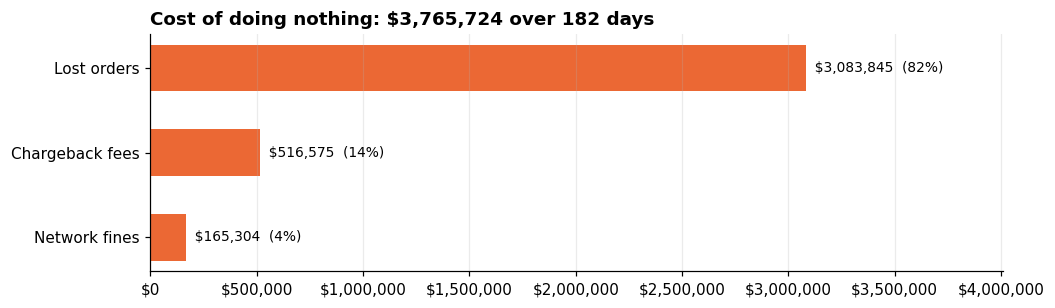

In [27]:
parts = m[["lost_orders_$", "chargeback_fees_$", "network_fines_$"]].sum()
parts.index = ["Lost orders", "Chargeback fees", "Network fines"]
parts = parts.sort_values()

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.barh(parts.index, parts.values, color=FRAUD, height=0.55)
for y, v in enumerate(parts.values):
    ax.text(v, y, f"  ${v:,.0f}  ({v / parts.sum():.0%})", va="center", fontsize=9)
ax.set_xlim(0, parts.max() * 1.3)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="y", visible=False)
ax.set_title(f"Cost of doing nothing: ${parts.sum():,.0f} over {n_days} days", loc="left")
save(fig, "09_cost_of_doing_nothing"); plt.show()

## 7. Is 100 manual reviews a day realistic?
The high-risk tier sends orders to analysts. With 100 reviews a day, what share of daily volume can they cover,
and how does that compare with the number of frauds per day?

In [28]:
daily = df.groupby("day")["isFraud"].agg(transactions="size", frauds="sum")
cap = ASSUMPTIONS["review_capacity_per_day"]

capacity = pd.Series({
    "Median transactions / day": f"{daily['transactions'].median():,.0f}",
    "Median frauds / day": f"{daily['frauds'].median():,.0f}",
    "Review capacity / day": f"{cap}",
    "Capacity as % of daily volume": f"{cap / daily['transactions'].median():.2%}",
    "Capacity as % of daily frauds": f"{cap / daily['frauds'].median():.0%}",
}, name="value")
capacity.to_frame()

,value
Median transactions / day,"3,050"
Median frauds / day,112
Review capacity / day,100
Capacity as % of daily volume,3.28%
Capacity as % of daily frauds,89%


**How to read this:** if there are more frauds per day than review slots, manual review alone can't solve the problem.
The model must push most risk into **automatic decline** or **step-up verification**, and reserve analysts for the most uncertain high-risk cases.
This is exactly the trade-off Step 4 will optimise.

## 8. Planned time-based split (used in Step 3)
Train on the earliest period, skip a ~30-day gap (mimicking chargebacks that haven't arrived yet), then test on the final ~30 days.

In [29]:
TEST_DAYS, GAP_DAYS = 30, 30
test_start = n_days - TEST_DAYS
gap_start  = test_start - GAP_DAYS

df["split"] = np.select([df["day"] < gap_start, df["day"] < test_start], ["train", "gap (unused)"], "test")
split = df.groupby("split", sort=False).agg(
    first_day=("day", "min"), last_day=("day", "max"),
    transactions=("isFraud", "size"), fraud_rate=("isFraud", "mean"))
split.loc[["train", "gap (unused)", "test"]]

,first_day,last_day,transactions,fraud_rate
split,,,,
train,0,121,420066,0.0352
gap (unused),122,151,85044,0.0339
test,152,181,85430,0.0350


## 9. Save the key numbers
These feed the business brief update and later notebooks. Download `step2_summary.json` and the `figures/` folder from the Output panel.

In [30]:
summary = {
    "n_transactions": n_tx,
    "n_fraud": n_fraud,
    "n_days": int(n_days),
    "median_daily_transactions": float(daily["transactions"].median()),
    "median_daily_frauds": float(daily["frauds"].median()),
    "avg_genuine_order_$": float(df.loc[~fraud, "TransactionAmt"].mean()),
    "avg_fraud_order_$": float(df.loc[fraud, "TransactionAmt"].mean()),
    **baseline,
    "assumptions": ASSUMPTIONS,
    "split": {"test_days": TEST_DAYS, "gap_days": GAP_DAYS, "gap_start_day": int(gap_start), "test_start_day": int(test_start)},
}
(OUT_DIR / "step2_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "n_transactions": 590540,
  "n_fraud": 20663,
  "n_days": 182,
  "median_daily_transactions": 3049.5,
  "median_daily_frauds": 112.5,
  "avg_genuine_order_$": 134.51166457849672,
  "avg_fraud_order_$": 149.24477858974976,
  "total_cost_$": 3765723.8599999994,
  "avg_monthly_cost_$": 618920.5194999999,
  "cost_pct_of_revenue": 0.04722565220310086,
  "fraud_ratio_count": 0.03499000914417313,
  "fraud_ratio_value": 0.03867426030720167,
  "months_over_vamp_limit": 7,
  "months_total": 7,
  "assumptions": {
    "chargeback_fee": 25.0,
    "vamp_fine": 8.0,
    "vamp_limit": 0.015,
    "target_ratio": 0.005,
    "review_capacity_per_day": 100
  },
  "split": {
    "test_days": 30,
    "gap_days": 30,
    "gap_start_day": 122,
    "test_start_day": 152
  }
}


## Findings

- **NovaCart is well above card-network limits every month.** 3.50% of transactions are fraudulent (20,663 of 590,540), 2.3× Visa's 1.5% VAMP limit and 7× our 0.5% target.
- **Fraud costs more in dollars than in count.** Fraud is 3.87% of revenue; the average fraud order is $149 vs $135 for genuine orders.
- **Fraud concentrates in identifiable segments.** Product type C (11.7%, about 3× average), credit cards (6.7% vs 2.4% for debit), Discover cards (7.7%) and outlook.com / hotmail.com purchasers (9.5% / 5.3%). By order size, risk peaks at **under $25 (7.0%)**, a pattern consistent with *card testing* (fraudsters checking stolen cards with small purchases), and again at **$200-$1k (4.5-5.8%)**, where the losses are larger.
- **Doing nothing costs about $619k a month (4.7% of revenue), over $20k for every day without screening.**
  Total cost = lost orders + chargeback fees ($25 each) + Visa VAMP fines ($8 each) = $3.08M + $0.52M + $0.17M = **$3.77M over 182 days**. This is the baseline every later step must beat.
- **Manual review cannot be the main defence.** About 3,050 orders and 113 frauds arrive per day against 100 review slots. Even a perfect model would overflow the queue, so most risk must be handled by automatic decline or step-up verification, with analysts reserved for the uncertain, high-value orders where their time saves the most money.
- **The fraud rate is stable enough to model, but we still split by time** (train → 30-day gap → test) to mimic production, where recent chargebacks haven't arrived yet.

**Next:** Step 3 trains a baseline LightGBM model and evaluates it on the final 30 days with PR-AUC.